# 18 — CartPole: 1-step On-policy Actor-Critic

현재 행동은 `Model.act()`로 선택하고 환경 step 직후 B=1을 즉시 학습한다. Replay나 Target Network는 없다. Policy와 Value는 같은 Representation을 쓰며 단일 Adam으로 학습한다.

### 실행 설정
`MODULARRL_FAST=1`은 CI용 FAST, 기본값은 FULL입니다. 각 Notebook은 독립 Kernel에서 실행합니다. 처음부터 Run All하면 RNG·Model·학습 상태를 다시 만듭니다.

In [1]:
from pathlib import Path
import os, sys, json
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import gymnasium as gym
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from copy import deepcopy
from collections import deque
from modular_rl import Model
from modular_rl import representations as R, estimators as E, selectors as S
from modular_rl import buffers as B, targets as T, updates as U, learners as L
from modular_rl.data import Transition, Episode
from modular_rl.dp import policy_evaluation, policy_iteration, value_iteration, uniform_policy, action_values
from notebooks.gymnasium.tutorial_utils import (frozenlake_mdp, evaluate, history, record, frozen_report, neural_report)
FAST = os.environ.get('MODULARRL_FAST', '0') == '1'  # 기본 FULL, CI는 FAST=1
SEED = 7
GAMMA = .99
np_rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.close('all')
print({'mode': 'FAST' if FAST else 'FULL', 'seed': SEED, 'gamma': GAMMA, 'device': 'cpu'})

{'mode': 'FULL', 'seed': 7, 'gamma': 0.99, 'device': 'cpu'}


### Loss와 Gradient 경계
\(y=r+\gamma(1-d)V(s')\), \(A=y-V(s)\).

\(L_{actor}=-\log\pi(a|s)\,stopgrad(A)\), \(L_{critic}=\tfrac12(V(s)-y)^2\),
\(L=L_{actor}+c_vL_{critic}-\beta H(\pi)\).

Learner는 현재 Policy에서 log_prob을 재계산한다. 수집 당시 detached log_prob은 기록용이다. Bootstrap은 no_grad이고 Actor Advantage만 detach한다. Critic과 Actor의 Gradient는 공유 Representation에 전달된다. 외부 Time-limit은 Bootstrap하되 에피소드는 종료한다.

In [2]:
env = gym.make('CartPole-v1', max_episode_steps=60 if FAST else 500)
eval_env = gym.make('CartPole-v1')
representation = R.MLP(4, hidden_dims=(64,), activation=nn.Tanh)
model = Model(representation, E.ActorCritic(E.CategoricalPolicy(64,2), E.StateValue(64)), S.Categorical())
optimizer = torch.optim.Adam(model.parameters(), lr=.001)
target_generator = T.TD0(GAMMA)
update_rule = U.ActorCritic(value_coef=.5, entropy_coef=.01)
learner = L.ActorCritic(model, optimizer, target_generator, update_rule)
STEP_BUDGET = 400 if FAST else 80000
model.eval()
before = evaluate(eval_env, lambda observation: model.act(observation, deterministic=True).action.item(),
                  episodes=3 if FAST else 20, seed=SEED+1000)
print('before mean return', np.mean(before['rewards']))
model.train()
log, losses, actor_losses, critic_losses, entropies, td_errors = history(), [], [], [], [], []
updates = []
observation, _ = env.reset(seed=SEED)
total, length = 0., 0

before mean return 9.2


In [3]:
try:
    for steps in range(1, STEP_BUDGET+1):
        selected = model.act(observation)
        next_observation, reward, terminated, truncated, _ = env.step(selected.action.item())
        cutoff = steps == STEP_BUDGET and not (terminated or truncated)
        truncated = truncated or cutoff
        transition = Transition(observation, selected.action, float(reward), next_observation,
                                terminated, truncated, selected.log_prob)
        result = learner.learn(transition.to_batch())  # 방금 수집한 B=1; 다음 행동 선택 전에 갱신
        losses.append(result.total_loss.item()); actor_losses.append(result.actor_loss.item())
        critic_losses.append(result.critic_loss.item()); entropies.append(result.entropy.item())
        td_errors.append(result.td_error.item())
        total += reward; length += 1; observation = next_observation
        if terminated or truncated:
            record(log, total, length, terminated, truncated); updates.append(steps)
            if len(log['rewards']) % (10 if FAST else 100) == 0:
                print('episode', len(log['rewards']), 'return', total, 'steps/updates', steps,
                      'actor', round(actor_losses[-1],4), 'critic', round(critic_losses[-1],4),
                      'entropy', round(entropies[-1],4))
            if steps < STEP_BUDGET:
                observation, _ = env.reset(); total, length = 0., 0
    model.eval()
    after = evaluate(eval_env, lambda observation: model.act(observation, deterministic=True).action.item(),
                     episodes=3 if FAST else 20, seed=SEED+1000)
    summary = dict(before=float(np.mean(before['rewards'])), after=float(np.mean(after['rewards'])),
                   episodes=len(log['rewards']), environment_steps=steps, gradient_updates=steps,
                   replay_reuse=False, gamma=GAMMA, value_coef=update_rule.value_coef,
                   entropy_coef=update_rule.entropy_coef, seed=SEED)
    print('RESULT', json.dumps(summary, sort_keys=True))
finally:
    env.close(); eval_env.close()

episode 100 return 18.0 steps/updates 3083 actor -38.3633 critic 266.1728 entropy 0.4857


episode 200 return 38.0 steps/updates 7872 actor -0.575 critic 496.2803 entropy 0.0905


episode 300 return 66.0 steps/updates 21300 actor -0.0616 critic 72.2692 entropy 0.0321


episode 400 return 329.0 steps/updates 33610 actor -1.5799 critic 1034.1464 entropy 0.1489


episode 500 return 92.0 steps/updates 44827 actor 0.0393 critic 12.7546 entropy 0.0454


episode 600 return 500.0 steps/updates 70807 actor 0.0005 critic 0.0014 entropy 0.0528


RESULT {"after": 500.0, "before": 9.2, "entropy_coef": 0.01, "environment_steps": 80000, "episodes": 619, "gamma": 0.99, "gradient_updates": 80000, "replay_reuse": false, "seed": 7, "value_coef": 0.5}


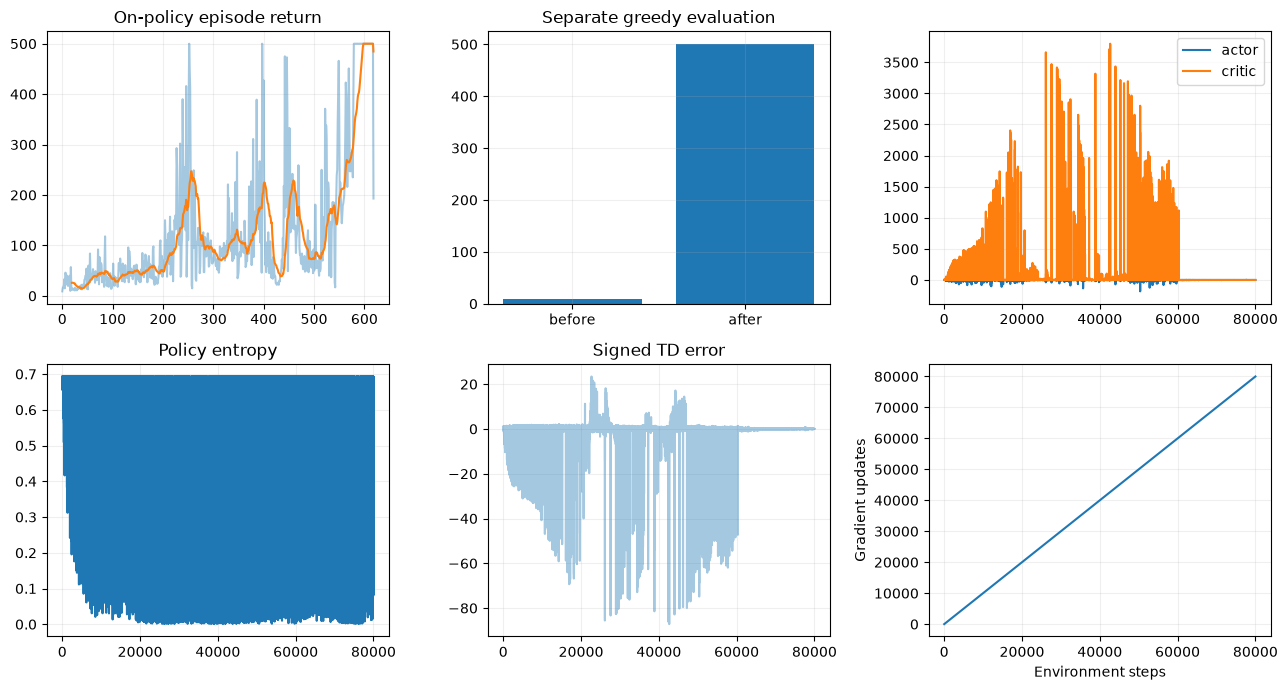

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13,7))
rewards = np.asarray(log['rewards']); window = min(20,len(rewards))
mean = np.convolve(rewards,np.ones(window)/window,mode='valid')
axes[0,0].plot(rewards,alpha=.4); axes[0,0].plot(np.arange(len(mean))+window-1,mean)
axes[0,0].set_title('On-policy episode return')
axes[0,1].bar(['before','after'],[summary['before'],summary['after']]); axes[0,1].set_title('Separate greedy evaluation')
axes[0,2].plot(actor_losses,label='actor'); axes[0,2].plot(critic_losses,label='critic'); axes[0,2].legend()
axes[1,0].plot(entropies); axes[1,0].set_title('Policy entropy')
axes[1,1].plot(td_errors,alpha=.4); axes[1,1].set_title('Signed TD error')
axes[1,2].plot(np.cumsum(log['lengths']),updates); axes[1,2].set(xlabel='Environment steps',ylabel='Gradient updates')
for ax in axes.flat: ax.grid(alpha=.2)
fig.tight_layout(); plt.show()

### DQN과의 데이터 사용 차이
Actor-Critic은 실제 step마다 새 경험을 한 번 사용하고 B=1으로 즉시 업데이트한다. DQN은 Warm-up 이후 B=64의 과거 Replay 경험을 반복 사용한다. 환경 step만 같다고 학습 계산량·데이터 재사용이 같은 비교가 아니다. 이 Notebook의 학습 성능은 수식·Gradient 테스트와 별도로 해석한다.

현재는 이산 Categorical 1-step 온라인 Actor-Critic이다. 연속 행동, A2C/A3C, PPO, GAE, 병렬 Rollout은 지원 범위가 아니다. Model과 단일 Optimizer의 state_dict, 환경·Torch RNG를 함께 저장하며 B>1 Replay를 On-policy 경험으로 취급하지 않는다.

### API 사용성 기록 — 아래 빈칸을 직접 수정해 보세요

|질문|실행 후 관찰/개선 제안|
|---|---|
|Model 생성이 자연스러운가?| |
|Learner 구성은 직관적인가?| |
|TargetGenerator를 선택하기 쉬운가?| |
|Buffer의 사용법이 일관적인가?| |
|Experience 자료형을 직접 조작할 필요가 있는가?| |
|학습 호출이 간결한가?| |
|Algorithm-specific 코드가 얼마나 필요한가?| |
|불필요한 자료형 변환이 존재하는가?| |
|API만 보고 학습 과정이 이해되는가?| |
|공용 컴포넌트로 옮길 필요가 있는 코드가 있는가?| |

FAST는 연결과 Shape 검사용이며 성능 판정이 아니다. FULL은 실제 학습용이다.
Seed 하나의 성공률로 알고리즘의 정확성을 판단하지 않는다. `terminated`와 `truncated`는
독립적인 flag이며 실제 마지막 관측을 저장한다. 아래 helper는 시각화·평가만 담당하고 학습을 숨기지 않는다.